# ML Zoomcamp 2026 — Homework 8
## Neural Networks and Deep Learning

### Objective
Build and evaluate a convolutional neural network (CNN) for binary image classification in PyTorch: curly hair (`0`) versus straight hair (`1`).

The official dataset contains a fixed training split (800 images) and held-out evaluation split (201 images). We train for 10 baseline epochs and then continue training for 10 additional epochs with data augmentation, retaining the same model and optimizer. The evaluation pipeline is unchanged.

**How to run:** Open this notebook in Google Colab, select a CPU runtime (Hardware accelerator: None) and choose **Runtime → Run all**. No manual upload of the dataset or reference script is needed. The Colab kernel orchestrates the experiment; all PyTorch training and model inspection run in the separate Python 3.11 CPU environment.

## 1. Reproducible environment
The Colab kernel's default Python version may differ from the homework specification. We use `uv` to create an isolated Python 3.11 environment with the exact reference CPU wheels. All framework-dependent operations below use that interpreter, without replacing the Colab kernel.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import json
import hashlib
import zipfile
import urllib.request

WORK_DIR = Path("/content/mlzoomcamp_hw08")
WORK_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORK_DIR)

REQUIREMENTS = """--index-url https://download.pytorch.org/whl/cpu
--extra-index-url https://pypi.org/simple
torch==2.9.0+cpu
torchvision==0.24.0+cpu
numpy==2.3.3
Pillow==11.3.0
"""
Path("requirements-cpu.txt").write_text(REQUIREMENTS, encoding="utf-8")
print(Path("requirements-cpu.txt").read_text())

--index-url https://download.pytorch.org/whl/cpu
--extra-index-url https://pypi.org/simple
torch==2.9.0+cpu
torchvision==0.24.0+cpu
numpy==2.3.3
Pillow==11.3.0



In [2]:
# Create the isolated Python 3.11 environment.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
uv = [sys.executable, "-m", "uv"]
subprocess.run(uv + ["python", "install", "3.11"], check=True)
ENV_DIR = WORK_DIR / "hw08-env"
PYTHON = ENV_DIR / "bin/python"
if not PYTHON.exists():
    subprocess.run(uv + ["venv", "--python", "3.11", str(ENV_DIR)], check=True)
subprocess.run(uv + ["pip", "install", "--python", str(PYTHON),
                     "--index-strategy", "unsafe-best-match", "-r", "requirements-cpu.txt"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'uv', 'pip', 'install', '--python', '/content/mlzoomcamp_hw08/hw08-env/bin/python', '--index-strategy', 'unsafe-best-match', '-r', 'requirements-cpu.txt'], returncode=0)

In [3]:
# Verify actual training environment; do not rely on the Colab kernel's versions.
version_check = """
import json, sys, torch, torchvision, numpy, PIL
versions = {
    'python': sys.version.split()[0], 'torch': torch.__version__,
    'torchvision': torchvision.__version__, 'numpy': numpy.__version__,
    'Pillow': PIL.__version__, 'device': str(torch.device('cpu')),
}
assert sys.version_info[:2] == (3, 11), versions
assert versions['torch'] == '2.9.0+cpu', versions
assert versions['torchvision'] == '0.24.0+cpu', versions
assert versions['numpy'] == '2.3.3', versions
assert versions['Pillow'] == '11.3.0', versions
print(json.dumps(versions, indent=2))
"""
versions = json.loads(subprocess.check_output([str(PYTHON), "-c", version_check], text=True))
Path("environment.json").write_text(json.dumps(versions, indent=2) + "\n", encoding="utf-8")
print(json.dumps(versions, indent=2))

{
  "python": "3.11.18",
  "torch": "2.9.0+cpu",
  "torchvision": "0.24.0+cpu",
  "numpy": "2.3.3",
  "Pillow": "11.3.0",
  "device": "cpu"
}


## 2. Dataset and integrity check
We use the official fixed archive. It contains 1,002 image files, including one GIF ignored by `ImageFolder`. We verify its SHA-256 checksum before extracting it. No random split is created.

| Split | Curly | Straight | Total |
|---|---:|---:|---:|
| Train | 410 | 390 | 800 |
| Held-out evaluation | 103 | 98 | 201 |

In [4]:
MANIFEST = json.loads('{"url": "https://github.com/SVizor42/ML_Zoomcamp/releases/download/straight-curly-data/data.zip", "sha256": "9e53453e3017502f22860cb08558f0cdb343e102fb61feab75960616185e7d67", "archive_entries": 1009, "image_files": 1002, "imagefolder_files": 1001, "classes": {"curly": {"train": 410, "test": 103}, "straight": {"train": 390, "test": 98}}, "class_index": {"curly": 0, "straight": 1}}')
Path("dataset_manifest.json").write_text(json.dumps(MANIFEST, indent=2) + "\n", encoding="utf-8")
archive = Path("data.zip")
def sha256(path):
    with path.open("rb") as f:
        return hashlib.file_digest(f, "sha256").hexdigest()

if not archive.exists() or sha256(archive) != MANIFEST["sha256"]:
    print("Downloading fixed dataset archive...", flush=True)
    urllib.request.urlretrieve(MANIFEST["url"], str(archive))
actual_sha256 = sha256(archive)
print(f"{actual_sha256}  {archive}")
assert actual_sha256 == MANIFEST["sha256"], "Dataset checksum mismatch"
with zipfile.ZipFile(archive) as z:
    assert len(z.infolist()) == MANIFEST["archive_entries"]
    z.extractall(WORK_DIR)
print("Dataset checksum verified and archive extracted.")

9e53453e3017502f22860cb08558f0cdb343e102fb61feab75960616185e7d67  data.zip
Dataset checksum verified and archive extracted.


In [5]:
# Check usable image counts and class mapping with the pinned torchvision version.
dataset_check = """
from collections import Counter
from torchvision.datasets import ImageFolder
from pathlib import Path
import json
manifest = json.loads(Path('dataset_manifest.json').read_text())
for split in ('train', 'test'):
    ds = ImageFolder(Path('data') / split)
    counts = Counter(ds.classes[target] for target in ds.targets)
    expected = {name: values[split] for name, values in manifest['classes'].items()}
    assert ds.class_to_idx == manifest['class_index'], ds.class_to_idx
    assert dict(counts) == expected, counts
    print(f'{split}: {len(ds)} images | {dict(counts)} | class mapping: {ds.class_to_idx}')
"""
print(subprocess.check_output([str(PYTHON), "-c", dataset_check], text=True))

train: 800 images | {'curly': 410, 'straight': 390} | class mapping: {'curly': 0, 'straight': 1}
test: 201 images | {'curly': 103, 'straight': 98} | class mapping: {'curly': 0, 'straight': 1}



## 3. CNN architecture and reference implementation
The complete official reference script is embedded below (copied unchanged from the supplied reference file). Running this cell writes `reference_train.py` locally, so the notebook does not depend on a changing GitHub branch.

| Operation | Output shape (one image) |
|---|---|
| RGB input | 3 × 200 × 200 |
| Conv2d + ReLU | 32 × 198 × 198 |
| MaxPool2d | 32 × 99 × 99 |
| Flatten | 313,632 |
| Linear + ReLU | 64 |
| Output linear layer | 1 logit |

The script sets the seed before creating datasets, loaders, the model and optimizer; uses CPU, two PyTorch threads and zero DataLoader workers; and uses dedicated generators (seed 42 for baseline, 43 for augmentation, as in the supplied reference script).

In [6]:
%%writefile reference_train.py
from __future__ import annotations

import argparse
import json
import random
import statistics
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


SEED = 42
BATCH_SIZE = 20
EPOCHS_PER_PHASE = 10
NORMALIZE = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


class HairModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.hidden = nn.Linear(32 * 99 * 99, 64)
        self.output = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv(x)))
        x = x.flatten(start_dim=1)
        x = nn.functional.relu(self.hidden(x))
        return self.output(x)


def evaluation_transform():
    return transforms.Compose([
        transforms.Resize(
            (200, 200),
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
        transforms.ToTensor(),
        NORMALIZE,
    ])


def augmented_train_transform():
    return transforms.Compose([
        transforms.Resize(
            (200, 200),
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
        transforms.RandomRotation(
            50,
            interpolation=transforms.InterpolationMode.NEAREST,
        ),
        transforms.RandomResizedCrop(
            200,
            scale=(0.9, 1.0),
            ratio=(0.9, 1.1),
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        NORMALIZE,
    ])


def make_loader(dataset, *, shuffle: bool, seed: int | None = None):
    options = {
        "batch_size": BATCH_SIZE,
        "shuffle": shuffle,
        "num_workers": 0,
    }
    if seed is not None:
        options["generator"] = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, **options)


def evaluate(model, loader, criterion, device):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)
            logits = model(images)
            loss = criterion(logits, labels)
            loss_sum += loss.item() * images.size(0)
            correct += ((torch.sigmoid(logits) >= 0.5) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total


def train_phase(model, loader, evaluation_loader, criterion, optimizer, device):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "evaluation_loss": [],
        "evaluation_accuracy": [],
    }
    for _ in range(EPOCHS_PER_PHASE):
        model.train()
        loss_sum = 0.0
        correct = 0
        total = 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * images.size(0)
            correct += ((torch.sigmoid(logits) >= 0.5) == labels).sum().item()
            total += labels.size(0)

        evaluation_loss, evaluation_accuracy = evaluate(
            model,
            evaluation_loader,
            criterion,
            device,
        )
        history["train_loss"].append(loss_sum / total)
        history["train_accuracy"].append(correct / total)
        history["evaluation_loss"].append(evaluation_loss)
        history["evaluation_accuracy"].append(evaluation_accuracy)
    return history


def run(data_dir: Path, output_dir: Path) -> None:
    seed_everything()
    torch.set_num_threads(2)
    device = torch.device("cpu")
    train_dir = data_dir / "train"
    evaluation_dir = data_dir / "test"

    baseline_dataset = datasets.ImageFolder(train_dir, transform=evaluation_transform())
    evaluation_dataset = datasets.ImageFolder(
        evaluation_dir,
        transform=evaluation_transform(),
    )
    if len(baseline_dataset) != 800 or len(evaluation_dataset) != 201:
        raise ValueError(
            "unexpected ImageFolder counts; verify the archive against "
            "dataset_manifest.json"
        )
    if baseline_dataset.class_to_idx != {"curly": 0, "straight": 1}:
        raise ValueError(f"unexpected class mapping: {baseline_dataset.class_to_idx}")

    evaluation_loader = make_loader(evaluation_dataset, shuffle=False)
    model = HairModel().to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.002, momentum=0.8)

    baseline = train_phase(
        model,
        make_loader(baseline_dataset, shuffle=True, seed=SEED),
        evaluation_loader,
        criterion,
        optimizer,
        device,
    )
    augmented_dataset = datasets.ImageFolder(
        train_dir,
        transform=augmented_train_transform(),
    )
    augmented = train_phase(
        model,
        make_loader(augmented_dataset, shuffle=True, seed=SEED + 1),
        evaluation_loader,
        criterion,
        optimizer,
        device,
    )

    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / "history_baseline.json").write_text(
        json.dumps(baseline, indent=2) + "\n",
        encoding="utf-8",
    )
    (output_dir / "history_augmented.json").write_text(
        json.dumps(augmented, indent=2) + "\n",
        encoding="utf-8",
    )
    summary = {
        "output_dir": str(output_dir),
        "parameters": sum(parameter.numel() for parameter in model.parameters()),
        "baseline_median_train_accuracy": statistics.median(
            baseline["train_accuracy"]
        ),
        "baseline_train_loss_std_population": float(
            np.std(baseline["train_loss"], ddof=0)
        ),
        "augmented_mean_evaluation_loss": statistics.mean(
            augmented["evaluation_loss"]
        ),
        "augmented_last_five_evaluation_accuracy": statistics.mean(
            augmented["evaluation_accuracy"][-5:]
        ),
    }
    print(json.dumps(summary, indent=2))


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", type=Path, default=Path("data"))
    parser.add_argument("--output-dir", type=Path, default=Path("runs/reference"))
    args = parser.parse_args()
    run(args.data_dir, args.output_dir)


Writing reference_train.py


### Question 1 — Loss function
The output is a single raw logit. `nn.BCEWithLogitsLoss()` combines binary cross-entropy and sigmoid in a numerically stable operation. We apply sigmoid only for predictions, not inside `HairModel`.

### Question 2 — Number of trainable parameters
Count weights and biases with `sum(p.numel() for p in model.parameters())`. The fully connected hidden layer dominates the total parameter count.

In [7]:
# Inspect the actual reference model in the pinned environment.
# This separate process does not consume any random state in the training run.
model_check = """
from reference_train import HairModel, seed_everything
import torch.nn as nn
import json
seed_everything()
model = HairModel()
counts = {name: sum(p.numel() for p in layer.parameters())
          for name, layer in model.named_children()}
print(json.dumps({'loss': type(nn.BCEWithLogitsLoss()).__name__,
                  'layers': counts,
                  'parameters': sum(p.numel() for p in model.parameters())}, indent=2))
"""
model_info = json.loads(subprocess.check_output([str(PYTHON), "-c", model_check], text=True))
assert model_info["parameters"] == 20073473
print(json.dumps(model_info, indent=2))

{
  "loss": "BCEWithLogitsLoss",
  "layers": {
    "conv": 896,
    "pool": 0,
    "hidden": 20072512,
    "output": 65
  },
  "parameters": 20073473
}


## 4. Training configuration
| Hyperparameter | Value |
|---|---|
| Device | CPU |
| Batch size | 20 |
| Optimizer | SGD |
| Learning rate | 0.002 |
| Momentum | 0.8 |
| Baseline epochs | 10 |
| Augmented epochs | 10 |

**Baseline:** Resize to 200 × 200 using bilinear interpolation, convert to tensor, and normalize using the specified channel statistics.

**Augmented training:** Add random rotation (±50°, nearest interpolation), random resized crop (scale 0.9–1.0, ratio 0.9–1.1) and random horizontal flip. The same model and optimizer continue training without reinitialization. The held-out transform and evaluation loader remain unchanged. Loss and accuracy are weighted by the number of examples.

The next cell launches the unchanged reference script in a fresh Python process. The script prints its summary only after all 20 epochs; absence of intermediate output is expected.

In [8]:
OUT_DIR = Path("runs/reference")
OUT_DIR.mkdir(parents=True, exist_ok=True)
# Remove previous history files so the reported results must come from this run.
for name in ("history_baseline.json", "history_augmented.json", "summary.json"):
    (OUT_DIR / name).unlink(missing_ok=True)

print("Starting CPU reference training: 10 baseline + 10 augmented epochs...", flush=True)
summary = json.loads(subprocess.check_output(
    [str(PYTHON), "-u", "reference_train.py", "--data-dir", "data",
     "--output-dir", str(OUT_DIR)], text=True))
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(json.dumps(summary, indent=2))

Starting CPU reference training: 10 baseline + 10 augmented epochs...
{
  "output_dir": "runs/reference",
  "parameters": 20073473,
  "baseline_median_train_accuracy": 0.808125,
  "baseline_train_loss_std_population": 0.13934083913625103,
  "augmented_mean_evaluation_loss": 0.5754194738556496,
  "augmented_last_five_evaluation_accuracy": 0.7233830845771144
}


## 5. Validate histories and answer Questions 3–6
Each history must contain exactly 10 values per metric. The following calculations use the JSON files generated by this run, not hard-coded answers. For Q4, the population standard deviation is used (`ddof=0` is equivalent to `statistics.pstdev`).

In [9]:
import statistics
import math
from IPython.display import display, Markdown

metrics = {"train_loss", "train_accuracy", "evaluation_loss", "evaluation_accuracy"}
def read_history(name):
    history = json.loads((OUT_DIR / name).read_text(encoding="utf-8"))
    assert set(history) == metrics
    for metric, values in history.items():
        assert len(values) == 10, (name, metric)
        assert all(math.isfinite(x) for x in values), (name, metric)
        assert all(x >= 0 for x in values), (name, metric)
        if metric.endswith("accuracy"):
            assert all(x <= 1 for x in values), (name, metric)
    print(f"{name}: all four series contain 10 epochs.")
    return history

baseline = read_history("history_baseline.json")
augmented = read_history("history_augmented.json")

q3 = statistics.median(baseline["train_accuracy"])
q4 = statistics.pstdev(baseline["train_loss"])
q5 = statistics.mean(augmented["evaluation_loss"])
q6 = statistics.mean(augmented["evaluation_accuracy"][-5:])
for key, value in {
    "baseline_median_train_accuracy": q3,
    "baseline_train_loss_std_population": q4,
    "augmented_mean_evaluation_loss": q5,
    "augmented_last_five_evaluation_accuracy": q6,
}.items():
    assert math.isclose(value, summary[key], rel_tol=1e-12, abs_tol=1e-12), key
assert summary["parameters"] == model_info["parameters"]
print("All calculations agree with the reference script summary.")

answers = {
    "Q1": "nn." + model_info["loss"] + "()",
    "Q2": str(model_info["parameters"]),
    "Q3": f"{q3:.2f}",
    "Q4": f"{q4:.3f}",
    "Q5": f"{q5:.3f}",
    "Q6": f"{q6:.2f}",
}
(OUT_DIR / "answers.json").write_text(json.dumps(answers, indent=2) + "\n", encoding="utf-8")
rows = [
    ("Q1", "Loss function", "—"),
    ("Q2", "Trainable parameters", answers["Q2"]),
    ("Q3", "Median baseline training accuracy", f"{q3:.9f}"),
    ("Q4", "Population std of baseline training loss", f"{q4:.9f}"),
    ("Q5", "Mean augmented evaluation loss", f"{q5:.9f}"),
    ("Q6", "Mean augmented evaluation accuracy (last 5 epochs)", f"{q6:.9f}"),
]
table = "| Question | Metric | Computed value | Submit |\n|---|---|---:|---:|\n"
table += "\n".join(f"| {q} | {label} | {raw} | **{answers[q]}** |" for q, label, raw in rows)
display(Markdown(table))

history_baseline.json: all four series contain 10 epochs.
history_augmented.json: all four series contain 10 epochs.
All calculations agree with the reference script summary.


| Question | Metric | Computed value | Submit |
|---|---|---:|---:|
| Q1 | Loss function | — | **nn.BCEWithLogitsLoss()** |
| Q2 | Trainable parameters | 20073473 | **20073473** |
| Q3 | Median baseline training accuracy | 0.808125000 | **0.81** |
| Q4 | Population std of baseline training loss | 0.139340839 | **0.139** |
| Q5 | Mean augmented evaluation loss | 0.575419474 | **0.575** |
| Q6 | Mean augmented evaluation accuracy (last 5 epochs) | 0.723383085 | **0.72** |

## 6. Learning curves
The dashed line marks the transition after baseline epoch 10. Training accuracy is measured on the augmented inputs in the second phase, while evaluation accuracy is always measured on the same unmodified held-out images.

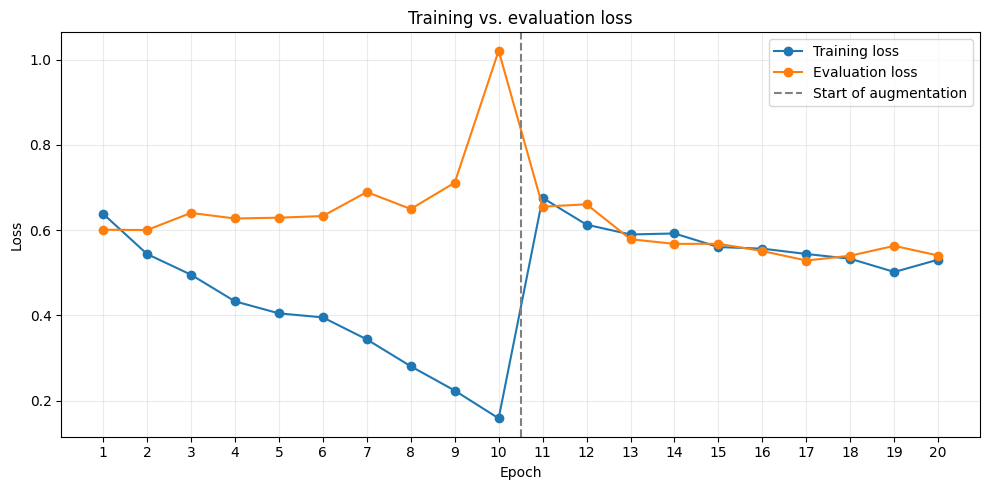

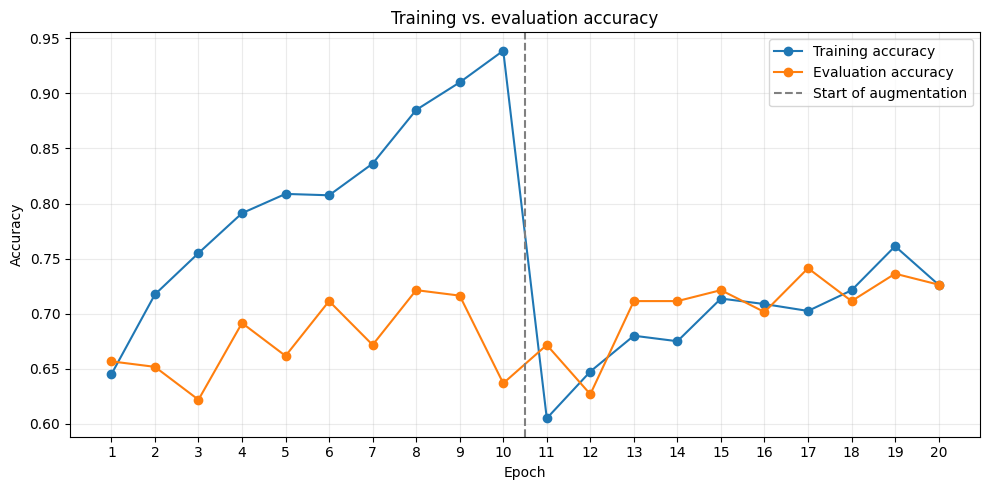

In [10]:
import matplotlib.pyplot as plt

epochs = range(1, 21)
for metric, ylabel, filename in [
    ("loss", "Loss", "loss_curves.png"),
    ("accuracy", "Accuracy", "accuracy_curves.png"),
]:
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(epochs, baseline[f"train_{metric}"] + augmented[f"train_{metric}"],
            marker="o", label=f"Training {metric}")
    ax.plot(epochs, baseline[f"evaluation_{metric}"] + augmented[f"evaluation_{metric}"],
            marker="o", label=f"Evaluation {metric}")
    ax.axvline(10.5, linestyle="--", color="gray", label="Start of augmentation")
    ax.set(xlabel="Epoch", ylabel=ylabel, title=f"Training vs. evaluation {metric}")
    ax.set_xticks(range(1, 21))
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 7. Discussion and conclusions
To assess generalization, compare evaluation metrics with evaluation metrics, rather than comparing baseline training accuracy with augmented evaluation accuracy. The following summary is generated from the current run.

In [11]:
comparison = {
    "Final training accuracy": (baseline["train_accuracy"][-1], augmented["train_accuracy"][-1]),
    "Final evaluation accuracy": (baseline["evaluation_accuracy"][-1], augmented["evaluation_accuracy"][-1]),
    "Mean evaluation accuracy": (statistics.mean(baseline["evaluation_accuracy"]), statistics.mean(augmented["evaluation_accuracy"])),
    "Best evaluation accuracy": (max(baseline["evaluation_accuracy"]), max(augmented["evaluation_accuracy"])),
    "Mean evaluation loss": (statistics.mean(baseline["evaluation_loss"]), statistics.mean(augmented["evaluation_loss"])),
}
table = "| Metric | Baseline | Augmented |\n|---|---:|---:|\n"
for metric, (b, a) in comparison.items():
    spec = ".2%" if "accuracy" in metric else ".3f"
    table += f"| {metric} | {b:{spec}} | {a:{spec}} |\n"
display(Markdown(table))
b_gap = baseline["train_accuracy"][-1] - baseline["evaluation_accuracy"][-1]
b_loss, a_loss = comparison["Mean evaluation loss"]
b_acc, a_acc = comparison["Mean evaluation accuracy"]
loss_direction = "decreased" if a_loss < b_loss else "increased" if a_loss > b_loss else "was unchanged"
acc_direction = "increased" if a_acc > b_acc else "decreased" if a_acc < b_acc else "was unchanged"
display(Markdown(
    f"The baseline ended with a training–evaluation accuracy gap of {b_gap:.2%} "
    f"(percentage-point difference). During the augmented phase, mean evaluation loss {loss_direction} "
    f"(from {b_loss:.3f} to {a_loss:.3f}), and mean evaluation accuracy {acc_direction} "
    f"(from {b_acc:.2%} to {a_acc:.2%}). The last five augmented epochs achieved "
    f"a mean held-out accuracy of {q6:.2%}."
))

| Metric | Baseline | Augmented |
|---|---:|---:|
| Final training accuracy | 93.88% | 72.62% |
| Final evaluation accuracy | 63.68% | 72.64% |
| Mean evaluation accuracy | 67.41% | 70.60% |
| Best evaluation accuracy | 72.14% | 74.13% |
| Mean evaluation loss | 0.680 | 0.575 |


The baseline ended with a training–evaluation accuracy gap of 30.19% (percentage-point difference). During the augmented phase, mean evaluation loss decreased (from 0.680 to 0.575), and mean evaluation accuracy increased (from 67.41% to 70.60%). The last five augmented epochs achieved a mean held-out accuracy of 72.34%.

### Conclusion

The baseline model showed signs of overfitting, reaching
93.88% training accuracy but only 63.68% evaluation accuracy.

During the augmented training phase, the mean evaluation
loss decreased from 0.680 to 0.575, while the mean
evaluation accuracy increased from 67.41% to 70.60%.

These results suggest improved generalization. However,
since the augmented phase continued from the baseline
model, the improvement cannot be attributed exclusively
to data augmentation.